# Analisis Sample Superstore: ETL, Data Warehouse, dan EDA


## Soal 1 - Memuat dan melihat struktur dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("samplesuperstore.csv")
data

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
10190,10191,US-2026-115427,12/30/2026,1/3/2027,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750
10191,10192,US-2026-156720,12/30/2026,1/3/2027,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,80538,West,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048
10192,10193,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

In [4]:
print(data.shape)
print("Missing value :", data.isnull().sum().sum())
print("Data duplikat :", data.duplicated().sum())
print("Jumlah order    :", data['Order ID'].nunique())
print("Jumlah customer :", data['Customer ID'].nunique())
print("Jumlah produk   :", data['Product ID'].nunique())

(10194, 21)
Missing value : 0
Data duplikat : 0
Jumlah order    : 5111
Jumlah customer : 804
Jumlah produk   : 1862


## Soal 2 - Grain, fact, dan dimension
Grain: 1 baris = 1 item produk dalam 1 order.  
Fact: `fact_sales` (sales, quantity, discount, profit).  
Dimension: `dim_date`, `dim_customer`, `dim_product`, `dim_geography`, `dim_ship_mode`.

## Soal 3 - ETL


### Pemeriksaan kualitas data mentah

In [5]:
# pemeriksaan kualitas data mentah (sebelum transformasi)
mentah = data.copy()
tgl_order = pd.to_datetime(mentah['Order Date'], format='%m/%d/%Y')
tgl_kirim = pd.to_datetime(mentah['Ship Date'], format='%m/%d/%Y')
lama_kirim = (tgl_kirim - tgl_order).dt.days
margin_hitung = (mentah['Profit'] / mentah['Sales']).round(4)

print("Missing value             :", mentah.isnull().sum().sum(), "dari", mentah.size, "sel")
print("Baris duplikat            :", mentah.duplicated().sum())
print("ship_date < order_date    :", (lama_kirim < 0).sum(), "baris; lama kirim", lama_kirim.min(), "-", lama_kirim.max(), "hari")
print("Rentang tanggal pesanan   :", tgl_order.min().date(), "s/d", tgl_order.max().date(), "|", tgl_order.nunique(), "hari bertransaksi")
print("Baris profit negatif      :", (mentah['Profit'] < 0).sum(), f"({(mentah['Profit'] < 0).mean()*100:.1f}%)")
print("Product ID > 1 nama       :", mentah.groupby('Product ID')['Product Name'].nunique().gt(1).sum())
print("Produk unik (Product ID)  :", mentah['Product ID'].nunique())

Missing value             : 0 dari 214074 sel
Baris duplikat            : 0
ship_date < order_date    : 0 baris; lama kirim 0 - 11 hari
Rentang tanggal pesanan   : 2023-01-03 s/d 2026-12-30 | 1242 hari bertransaksi
Baris profit negatif      : 1901 (18.6%)
Product ID > 1 nama       : 32
Produk unik (Product ID)  : 1862


In [6]:
df = data.copy()
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
10190,10191,US-2026-115427,12/30/2026,1/3/2027,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750
10191,10192,US-2026-156720,12/30/2026,1/3/2027,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,80538,West,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048
10192,10193,US-2026-143259,12/30/2026,1/3/2027,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279


In [7]:
# 1. standarisasi nama kolom
df.columns = [c.strip().lower().replace('/', '_').replace(' ', '_').replace('-', '_') for c in df.columns]
df.columns

Index(['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode',
       'customer_id', 'customer_name', 'segment', 'country_region', 'city',
       'state_province', 'postal_code', 'region', 'product_id', 'category',
       'sub_category', 'product_name', 'sales', 'quantity', 'discount',
       'profit'],
      dtype='object')

In [8]:
# 2. hapus duplikat
df = df.drop_duplicates()
df.shape

(10194, 21)

In [9]:
# 3. ubah tipe tanggal
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y')
df['ship_date'] = pd.to_datetime(df['ship_date'], format='%m/%d/%Y')
df[['order_date', 'ship_date']].head()

,order_date,ship_date
0,2023-01-03,2023-01-07
1,2023-01-04,2023-01-08
2,2023-01-04,2023-01-08
3,2023-01-04,2023-01-08
4,2023-01-05,2023-01-12


In [10]:
# 4. postal code jadi string 5 digit, 5. trim teks
df['postal_code'] = df['postal_code'].astype(str).str.zfill(5)
for c in ['customer_name', 'city', 'product_name']:
    df[c] = df[c].str.strip()

In [11]:
# 6. kolom turunan
df['ship_days'] = (df['ship_date'] - df['order_date']).dt.days
df['profit_margin'] = (df['profit'] / df['sales']).round(4)
df['is_loss'] = (df['profit'] < 0).astype(int)
df[['order_date', 'ship_date', 'ship_days', 'sales', 'profit', 'profit_margin', 'is_loss']].head()

,order_date,ship_date,ship_days,sales,profit,profit_margin,is_loss
0,2023-01-03,2023-01-07,4,16.448,5.5512,0.3375,0
1,2023-01-04,2023-01-08,4,3.540,-5.4870,-1.5500,1
2,2023-01-04,2023-01-08,4,11.784,4.2717,0.3625,0
3,2023-01-04,2023-01-08,4,272.736,-64.7748,-0.2375,1
4,2023-01-05,2023-01-12,7,19.536,4.8840,0.2500,0


In [12]:
# 7. binning diskon
df['discount_band'] = pd.cut(df['discount'], [-0.01, 0, 0.2, 0.4, 1],
                             labels=['0%', '1-20%', '21-40%', '>40%']).astype(str)
df[['discount', 'discount_band']].head()

,discount,discount_band
0,0.2,1-20%
1,0.8,>40%
2,0.2,1-20%
3,0.2,1-20%
4,0.2,1-20%


In [13]:
# 8. cek integritas produk (1 product_id > 1 nama)
print(df.groupby('product_id')['product_name'].nunique().gt(1).sum())

32


In [14]:
# 9. bentuk tabel dimensi + surrogate key
prod = df.sort_values('order_date').drop_duplicates('product_id')[['product_id', 'product_name', 'category', 'sub_category']]
cust = df.drop_duplicates('customer_id')[['customer_id', 'customer_name', 'segment']]
geo = df.drop_duplicates(['city', 'state_province', 'postal_code'])[['city', 'state_province', 'postal_code', 'region', 'country_region']]
ship = df[['ship_mode']].drop_duplicates()

dates = pd.DataFrame({'full_date': pd.date_range(df['order_date'].min(), df['ship_date'].max())})
dates['date_key'] = dates['full_date'].dt.strftime('%Y%m%d').astype(int)
dates['year'] = dates['full_date'].dt.year
dates['quarter'] = dates['full_date'].dt.quarter
dates['month'] = dates['full_date'].dt.month
dates['month_name'] = dates['full_date'].dt.month_name()
dates['day_name'] = dates['full_date'].dt.day_name()

for tabel, key in [(prod, 'product_key'), (cust, 'customer_key'), (geo, 'geo_key'), (ship, 'ship_mode_key')]:
    tabel.reset_index(drop=True, inplace=True)
    tabel.insert(0, key, tabel.index + 1)

In [15]:
# 10. bentuk fact table
fact = (df.merge(prod[['product_key', 'product_id']], on='product_id')
          .merge(cust[['customer_key', 'customer_id']], on='customer_id')
          .merge(geo[['geo_key', 'city', 'state_province', 'postal_code']], on=['city', 'state_province', 'postal_code'])
          .merge(ship, on='ship_mode'))
fact['order_date_key'] = fact['order_date'].dt.strftime('%Y%m%d').astype(int)
fact['ship_date_key'] = fact['ship_date'].dt.strftime('%Y%m%d').astype(int)
fact = fact[['row_id', 'order_id', 'order_date_key', 'ship_date_key', 'customer_key', 'product_key', 'geo_key',
             'ship_mode_key', 'sales', 'quantity', 'discount', 'profit', 'profit_margin', 'ship_days', 'is_loss', 'discount_band']]
fact.head()

,row_id,order_id,order_date_key,ship_date_key,customer_key,product_key,geo_key,ship_mode_key,sales,quantity,discount,profit,profit_margin,ship_days,is_loss,discount_band
0,1,US-2023-103800,20230103,20230107,1,1,1,1,16.448,2,0.2,5.5512,0.3375,4,0,1-20%
1,400,US-2023-157406,20230425,20230429,166,351,1,1,6.240,3,0.2,0.5460,0.0875,4,0,1-20%
2,401,US-2023-157406,20230425,20230429,166,352,1,1,10.368,2,0.2,3.6288,0.3500,4,0,1-20%
3,5088,US-2025-166240,20250624,20250628,534,1521,1,1,8.712,2,0.8,-19.6020,-2.2500,4,1,>40%
4,692,US-2023-116757,20230630,20230704,283,8,1,1,25.920,5,0.2,9.0720,0.3500,4,0,1-20%


In [16]:
tabel_dw = {'dim_product': prod, 'dim_customer': cust, 'dim_geography': geo, 'dim_ship_mode': ship,
            'dim_date': dates, 'fact_sales': fact}
for nama, tabel in tabel_dw.items():
    print(nama, len(tabel), 'baris')

# ekspor data warehouse ke Excel (butuh openpyxl: pip install openpyxl)
with pd.ExcelWriter("superstore_dw.xlsx") as writer:
    for nama, tabel in tabel_dw.items():
        tabel.to_excel(writer, sheet_name=nama, index=False)
print("Tersimpan: superstore_dw.xlsx")

dim_product 1862 baris
dim_customer 804 baris
dim_geography 655 baris
dim_ship_mode 4 baris
dim_date 1464 baris
fact_sales 10194 baris
Tersimpan: superstore_dw.xlsx


In [17]:
# contoh isi data warehouse
for nama in ['fact_sales', 'dim_product', 'dim_customer', 'dim_geography', 'dim_ship_mode']:
    print(nama)
    display(tabel_dw[nama].head())

fact_sales


,row_id,order_id,order_date_key,ship_date_key,customer_key,product_key,geo_key,ship_mode_key,sales,quantity,discount,profit,profit_margin,ship_days,is_loss,discount_band
0,1,US-2023-103800,20230103,20230107,1,1,1,1,16.448,2,0.2,5.5512,0.3375,4,0,1-20%
1,400,US-2023-157406,20230425,20230429,166,351,1,1,6.240,3,0.2,0.5460,0.0875,4,0,1-20%
2,401,US-2023-157406,20230425,20230429,166,352,1,1,10.368,2,0.2,3.6288,0.3500,4,0,1-20%
3,5088,US-2025-166240,20250624,20250628,534,1521,1,1,8.712,2,0.8,-19.6020,-2.2500,4,1,>40%
4,692,US-2023-116757,20230630,20230704,283,8,1,1,25.920,5,0.2,9.0720,0.3500,4,0,1-20%


dim_product


,product_key,product_id,product_name,category,sub_category
0,1,OFF-PA-10000174,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",Office Supplies,Paper
1,2,OFF-BI-10004094,GBC Standard Plastic Binding Systems Combs,Office Supplies,Binders
2,3,OFF-LA-10003223,Avery 508,Office Supplies,Labels
3,4,OFF-ST-10002743,SAFCO Boltless Steel Shelving,Office Supplies,Storage
4,5,OFF-AR-10003478,Avery Hi-Liter EverBold Pen Style Fluorescent ...,Office Supplies,Art


dim_customer


,customer_key,customer_id,customer_name,segment
0,1,DP-13000,Darren Powers,Consumer
1,2,PO-19195,Phillina Ober,Home Office
2,3,MB-18085,Mick Brown,Consumer
3,4,ME-17320,Maria Etezadi,Home Office
4,5,JO-15145,Jack O'Briant,Corporate


dim_geography


,geo_key,city,state_province,postal_code,region,country_region
0,1,Houston,Texas,77095,Central,United States
1,2,Naperville,Illinois,60540,Central,United States
2,3,Philadelphia,Pennsylvania,19143,East,United States
3,4,Henderson,Kentucky,42420,South,United States
4,5,Athens,Georgia,30605,South,United States


dim_ship_mode


,ship_mode_key,ship_mode
0,1,Standard Class
1,2,First Class
2,3,Second Class
3,4,Same Day


In [18]:
# validasi: total sales sebelum dan sesudah ETL
dw = (fact.merge(prod[['product_key', 'category', 'sub_category']], on='product_key', how='left', validate='m:1')
          .merge(cust[['customer_key', 'segment']], on='customer_key', how='left', validate='m:1')
          .merge(geo[['geo_key', 'region', 'state_province']], on='geo_key', how='left', validate='m:1')
          .merge(ship, on='ship_mode_key', how='left', validate='m:1')
          .merge(dates[['date_key', 'year', 'month']], left_on='order_date_key', right_on='date_key', how='left', validate='m:1')
          .drop(columns='date_key'))
print("Baris fakta tanpa dimensi:", dw[['category', 'segment', 'region', 'ship_mode', 'year']].isnull().any(axis=1).sum())
print("Jumlah baris fakta vs data mentah:", len(dw), len(data))
print(round(data['Sales'].sum(), 2), round(dw['sales'].sum(), 2))

Baris fakta tanpa dimensi: 0
Jumlah baris fakta vs data mentah: 10194 10194
2326534.35 2326534.35


### Contoh proses Transform: penelusuran satu pesanan (US-2023-112326)

In [19]:
oid = 'US-2023-112326'
print("Data mentah")
display(data[data['Order ID'] == oid][['Row ID', 'Order Date', 'Ship Date', 'Product ID', 'Sales', 'Quantity', 'Discount', 'Profit']])
print("Hasil transform pada fact_sales")
f_ord = fact[fact['order_id'] == oid]
display(f_ord)

Data mentah


,Row ID,Order Date,Ship Date,Product ID,Sales,Quantity,Discount,Profit
1,2,1/4/2023,1/8/2023,OFF-BI-10004094,3.540,2,0.8,-5.4870
2,3,1/4/2023,1/8/2023,OFF-LA-10003223,11.784,3,0.2,4.2717
3,4,1/4/2023,1/8/2023,OFF-ST-10002743,272.736,3,0.2,-64.7748


Hasil transform pada fact_sales


,row_id,order_id,order_date_key,ship_date_key,customer_key,product_key,geo_key,ship_mode_key,sales,quantity,discount,profit,profit_margin,ship_days,is_loss,discount_band
1577,2,US-2023-112326,20230104,20230108,2,2,2,1,3.540,2,0.8,-5.4870,-1.5500,4,1,>40%
1578,3,US-2023-112326,20230104,20230108,2,3,2,1,11.784,3,0.2,4.2717,0.3625,4,0,1-20%
1579,4,US-2023-112326,20230104,20230108,2,4,2,1,272.736,3,0.2,-64.7748,-0.2375,4,1,1-20%


In [20]:
print("dim_date")
display(dates[dates['date_key'].isin(f_ord['order_date_key'].tolist() + f_ord['ship_date_key'].tolist())])
print("dim_ship_mode")
display(ship[ship['ship_mode_key'].isin(f_ord['ship_mode_key'])])
print("dim_product")
display(prod[prod['product_key'].isin(f_ord['product_key'])])
print("dim_customer")
display(cust[cust['customer_key'].isin(f_ord['customer_key'])])
print("dim_geography")
display(geo[geo['geo_key'].isin(f_ord['geo_key'])])

dim_date


,full_date,date_key,year,quarter,month,month_name,day_name
1,2023-01-04,20230104,2023,1,1,January,Wednesday
5,2023-01-08,20230108,2023,1,1,January,Sunday


dim_ship_mode


,ship_mode_key,ship_mode
0,1,Standard Class


dim_product


,product_key,product_id,product_name,category,sub_category
1,2,OFF-BI-10004094,GBC Standard Plastic Binding Systems Combs,Office Supplies,Binders
2,3,OFF-LA-10003223,Avery 508,Office Supplies,Labels
3,4,OFF-ST-10002743,SAFCO Boltless Steel Shelving,Office Supplies,Storage


dim_customer


,customer_key,customer_id,customer_name,segment
1,2,PO-19195,Phillina Ober,Home Office


dim_geography


,geo_key,city,state_province,postal_code,region,country_region
1,2,Naperville,Illinois,60540,Central,United States


## Soal 4 - EDA
### Statistik deskriptif

In [21]:
dw[['sales', 'quantity', 'discount', 'profit']].describe().round(2)

,sales,quantity,discount,profit
count,10194.00,10194.00,10194.00,10194.00
mean,228.23,3.79,0.16,28.67
std,619.91,2.23,0.21,232.47
min,0.44,1.00,0.00,-6599.98
25%,17.22,2.00,0.00,1.76
50%,53.91,3.00,0.20,8.69
75%,209.50,5.00,0.20,29.30
max,22638.48,14.00,0.80,8399.98


In [22]:
print("Total sales  :", round(dw['sales'].sum()))
print("Total profit :", round(dw['profit'].sum()))
print("Margin       :", round(dw['profit'].sum() / dw['sales'].sum() * 100, 1), "%")
print("Transaksi rugi:", round(dw['is_loss'].mean() * 100, 1), "%")

Total sales  : 2326534
Total profit : 292297
Margin       : 12.6 %
Transaksi rugi: 18.6 %


In [23]:
dw[['sales', 'quantity', 'discount', 'profit']].corr().round(2)

,sales,quantity,discount,profit
sales,1.00,0.20,-0.03,0.48
quantity,0.20,1.00,0.01,0.07
discount,-0.03,0.01,1.00,-0.22
profit,0.48,0.07,-0.22,1.00


In [24]:
for kolom in ['year', 'category', 'region', 'segment']:
    display(dw.groupby(kolom)[['sales', 'profit']].sum().round(0))

,sales,profit
year,,
2023,494040.0,51684.0
2024,472993.0,62021.0
2025,613934.0,82665.0
2026,745568.0,95926.0


,sales,profit
category,,
Furniture,754748.0,19730.0
Office Supplies,731893.0,126023.0
Technology,839893.0,146543.0


,sales,profit
region,,
Central,503171.0,39865.0
East,691828.0,94883.0
South,391722.0,46749.0
West,739814.0,110799.0


,sales,profit
segment,,
Consumer,1170660.0,136371.0
Corporate,715806.0,94250.0
Home Office,440068.0,61676.0


### Visualisasi 1 - Tren sales dan profit

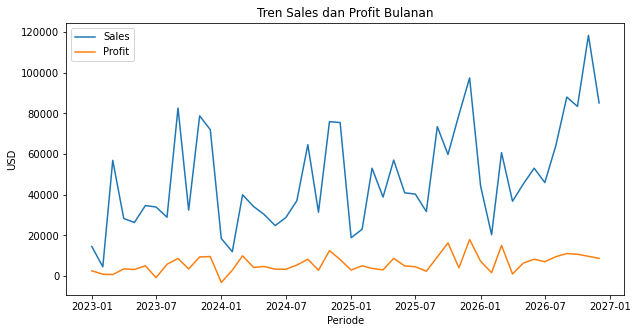

In [25]:
tren = dw.groupby(['year', 'month'])[['sales', 'profit']].sum().reset_index()
tren['periode'] = pd.to_datetime(dict(year=tren['year'], month=tren['month'], day=1))

plt.figure(figsize=(10, 5))
sns.lineplot(x='periode', y='sales', data=tren, label='Sales')
sns.lineplot(x='periode', y='profit', data=tren, label='Profit')
plt.title('Tren Sales dan Profit Bulanan')
plt.xlabel('Periode')
plt.ylabel('USD')
plt.show()

### Visualisasi 2 - Profit per sub-kategori

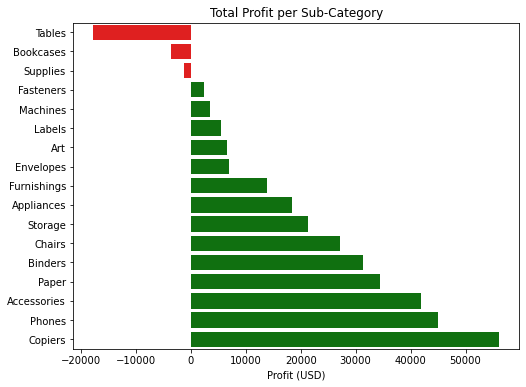

In [26]:
sub = dw.groupby('sub_category')['profit'].sum().sort_values().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='profit', y='sub_category', data=sub,
            palette=['red' if p < 0 else 'green' for p in sub['profit']])
plt.title('Total Profit per Sub-Category')
plt.xlabel('Profit (USD)')
plt.ylabel('')
plt.show()

### Visualisasi 3 - Diskon vs profit

,count,sum,mean
discount_band,,,
0%,4925,326718.6,66.3
1-20%,3854,101598.9,26.4
21-40%,464,-35991.0,-77.6
>40%,951,-100029.7,-105.2


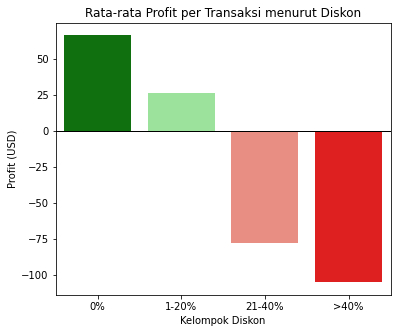

In [27]:
urutan = ['0%', '1-20%', '21-40%', '>40%']
diskon = dw.groupby('discount_band')['profit'].agg(['count', 'sum', 'mean']).reindex(urutan).round(1)
display(diskon)

plt.figure(figsize=(6, 5))
sns.barplot(x=diskon.index, y=diskon['mean'], palette=['green', 'lightgreen', 'salmon', 'red'])
plt.axhline(0, color='black', linewidth=1)
plt.title('Rata-rata Profit per Transaksi menurut Diskon')
plt.xlabel('Kelompok Diskon')
plt.ylabel('Profit (USD)')
plt.show()

### Visualisasi 4 - Margin Region x Category

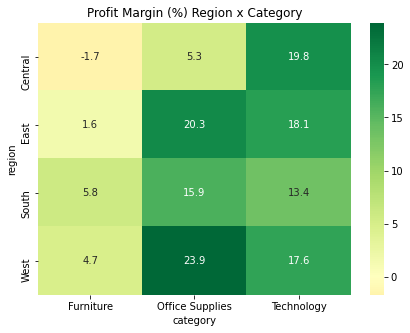

In [28]:
h = dw.groupby(['region', 'category'])[['profit', 'sales']].sum()
margin = (h['profit'] / h['sales'] * 100).unstack().round(1)

plt.figure(figsize=(7, 5))
sns.heatmap(margin, annot=True, fmt='.1f', cmap='RdYlGn', center=0)
plt.title('Profit Margin (%) Region x Category')
plt.show()

Interpretasi: Furniture di Central bermargin negatif (-1,7%), sedangkan Office Supplies di West mencapai 23,9%.

In [29]:
dw.groupby('state_province')['profit'].sum().sort_values().head(5).round(0)

state_province
Texas            -25729.0
Ohio             -16971.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0
Name: profit, dtype: float64